# Лабораторная работа №1
## «Марковские цепи. Статистическое оценивание»

**Курс:** Модели надёжности АСОИУ
**Студент:** Пермяков Дмитрий Кириллович
**Группа:** ИУ5-22М
**Вариант:** 18

---

### Цель работы
Изучить поведение однородных Марковских цепей (МЦ) методом статистических испытаний (Монте‑Карло):
1. Оценить **стационарные вероятности** возвратной МЦ по выборочным траекториям и сравнить со значением, полученным аналитически.
2. На примере **«задачи о разорении игрока»** оценить вероятности перехода в **поглощающие состояния** методом статистических испытаний.
3. Изучить **связь количества поглощающих состояний и собственных значений** матрицы переходных вероятностей.

### Задание (3 части)
- **Задание 1.** Программа генерации выборочных траекторий МЦ со случайной матрицей переходных вероятностей; графики оценок частот пребывания в каждом состоянии и гистограмма; сравнение со стационарными вероятностями.
- **Задание 2.** Программа расчёта вероятностей разорения в виде модели МЦ случайного блуждания с двумя поглощающими экранами; графики зависимости вероятности разорения от начального капитала и вероятности выигрыша.
- **Задание 3.** Программа генерации матриц переходных вероятностей МЦ с 2, 3 и более поглощающими состояниями; расчёт собственных значений и вывод о связи их количества с числом поглощающих состояний.


In [2]:
# !pip install numpy matplotlib scipy -q

import numpy as np
import matplotlib.pyplot as plt
from numpy.linalg import eig, solve

VARIANT = 18
SEED    = 18
np.random.seed(SEED)

plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.grid'] = True
print(f'Вариант: {VARIANT}, seed = {SEED}')


Вариант: 18, seed = 18


## Задание 1. Статистическое оценивание стационарных вероятностей возвратной МЦ

**Теория.** Однородная Марковская цепь задаётся матрицей переходных вероятностей $P=\|p_{ij}\|$, где $p_{ij} \ge 0$, $\sum_j p_{ij}=1$. Для возвратной (эргодической) МЦ существуют стационарные вероятности $\pi_i$ — предельные доли времени пребывания в каждом состоянии:

$$\pi P = \pi, \qquad \sum_i \pi_i = 1.$$

Эти же доли можно оценить **статистически** — сгенерировать длинную траекторию МЦ и подсчитать частоту попадания в каждое состояние.

**В общем, что делаем:**
1. Генерируем случайную стохастическую матрицу размера $n\times n$.
2. Имитируем траекторию длины $N$.
3. Накапливаем частоты состояний и строим графики оценок $\hat\pi_i(k)$ по мере роста $k$.
4. Решаем аналитически $\pi P = \pi$ и сравниваем с оценкой.


In [3]:
n = 5            # размер цепи (число состояний)
N = 10000        # длина выборочной траектории

# 1) Случайная стохастическая матрица переходных вероятностей
M = np.random.rand(n, n)
P = M / M.sum(axis=1, keepdims=True)   # нормировка по строкам: sum_j p_ij = 1
print('Матрица переходных вероятностей P (по строкам сумма = 1):')
print(np.round(P, 4))
print('Контроль сумм по строкам:', np.round(P.sum(axis=1), 6))


Матрица переходных вероятностей P (по строкам сумма = 1):
[[0.212  0.1647 0.2863 0.0593 0.2777]
 [0.2789 0.2477 0.3673 0.0955 0.0105]
 [0.2703 0.3603 0.3131 0.0088 0.0475]
 [0.1102 0.2542 0.3189 0.0735 0.2432]
 [0.2452 0.1235 0.2768 0.2853 0.0692]]
Контроль сумм по строкам: [1. 1. 1. 1. 1.]


In [4]:
# 2) Имитация траектории МЦ методом обратной функции распределения
def simulate_chain(P, N, start=0, rng=None):
    rng = rng or np.random.default_rng()
    n = P.shape[0]
    cum = P.cumsum(axis=1)             # кумулятивные строки
    states = np.empty(N, dtype=int)
    s = start
    for k in range(N):
        states[k] = s
        r = rng.random()
        s = int(np.searchsorted(cum[s], r))
    return states

rng = np.random.default_rng(SEED)
traj = simulate_chain(P, N, start=0, rng=rng)
print('Первые 30 состояний траектории:', traj[:30])


Первые 30 состояний траектории: [0 2 2 1 0 4 2 2 1 1 0 1 2 2 2 3 0 4 3 2 2 0 2 2 0 4 0 1 2 1]


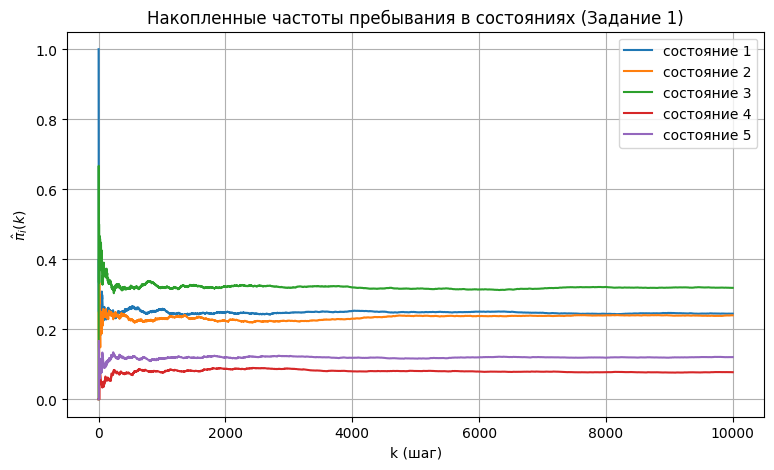

In [5]:
# 3) Накопленные частоты пребывания в каждом состоянии
visits = np.zeros((n, N), dtype=int)
for k, s in enumerate(traj):
    visits[s, k] = 1
cum_visits = visits.cumsum(axis=1)
freqs = cum_visits / np.arange(1, N + 1)   # оценка pi_i(k) на каждом шаге

# График: эволюция оценок частот
plt.figure()
for i in range(n):
    plt.plot(freqs[i], label=f'состояние {i+1}', linewidth=1.5)
plt.title('Накопленные частоты пребывания в состояниях (Задание 1)')
plt.xlabel('k (шаг)')
plt.ylabel(r'$\hat\pi_i(k)$')
plt.legend()
plt.show()


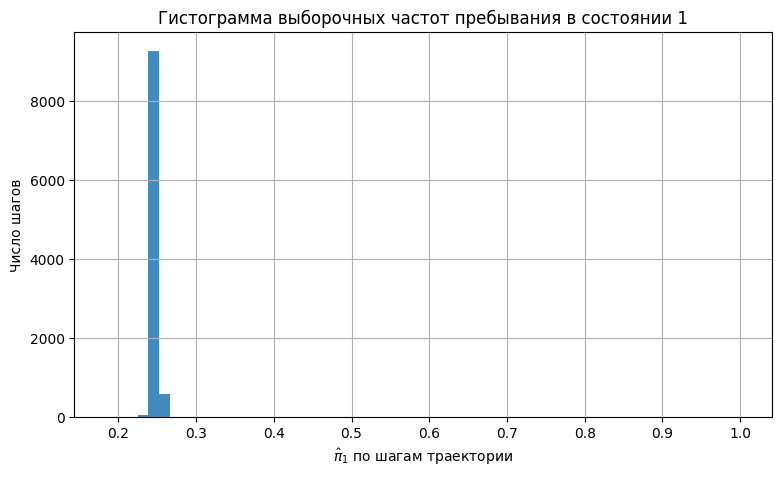

In [6]:
# 4) Гистограмма распределения частот пребывания (для состояния 1)
plt.figure()
plt.hist(freqs[0], bins=60, alpha=0.85)
plt.title('Гистограмма выборочных частот пребывания в состоянии 1')
plt.xlabel(r'$\hat\pi_1$ по шагам траектории')
plt.ylabel('Число шагов')
plt.show()


In [7]:
# 5) Аналитическое решение pi P = pi с условием нормировки
# Решаем систему: pi (P - I) = 0,  sum pi = 1
A = P.T - np.eye(n)
A[-1, :] = 1.0          # заменяем последнее уравнение нормировкой
b = np.zeros(n); b[-1] = 1.0
pi_theory = solve(A, b)

pi_emp = freqs[:, -1]   # последняя колонка = итоговая оценка
print('Стационарные вероятности (аналитика vs статистика):')
print(f'{"i":>3}  {"теор.":>10}  {"стат.":>10}  {"|разн.|":>10}')
for i in range(n):
    print(f'{i+1:>3}  {pi_theory[i]:>10.5f}  {pi_emp[i]:>10.5f}  {abs(pi_theory[i]-pi_emp[i]):>10.5f}')


Стационарные вероятности (аналитика vs статистика):
  i       теор.       стат.     |разн.|
  1     0.24286     0.24450     0.00164
  2     0.24979     0.23970     0.01009
  3     0.31652     0.31820     0.00168
  4     0.07881     0.07720     0.00161
  5     0.11202     0.12040     0.00838


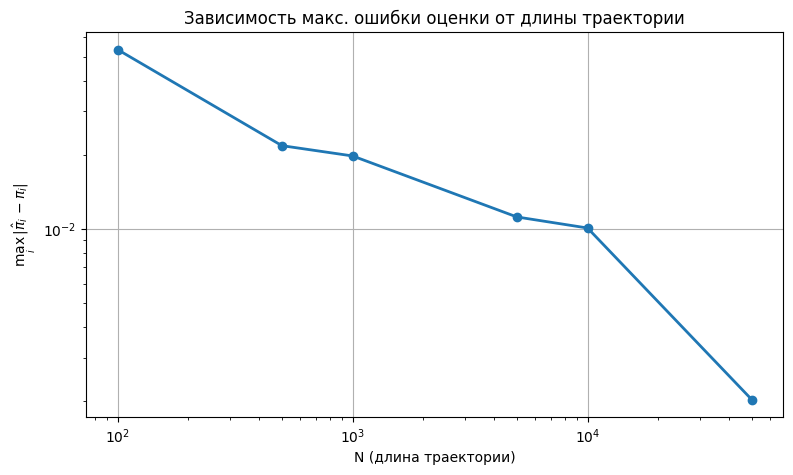

N=   100: max|err| = 0.05348
N=   500: max|err| = 0.02179
N=  1000: max|err| = 0.01979
N=  5000: max|err| = 0.01119
N= 10000: max|err| = 0.01009
N= 50000: max|err| = 0.00203


In [8]:
# 6) Влияние длины траектории N на точность оценки
Ns = [100, 500, 1000, 5000, 10000, 50000]
errors = []
for Nk in Ns:
    rng_k = np.random.default_rng(SEED)
    tr = simulate_chain(P, Nk, start=0, rng=rng_k)
    counts = np.bincount(tr, minlength=n) / Nk
    errors.append(np.max(np.abs(counts - pi_theory)))

plt.figure()
plt.loglog(Ns, errors, 'o-', linewidth=2)
plt.title('Зависимость макс. ошибки оценки от длины траектории')
plt.xlabel('N (длина траектории)')
plt.ylabel(r'$\max_i\,|\hat\pi_i - \pi_i|$')
plt.show()
for N_, e in zip(Ns, errors):
    print(f'N={N_:>6}: max|err| = {e:.5f}')


## Задание 2. Расчёт вероятностей перехода в поглощающие состояния (задача о разорении игрока)

**Модель.** Случайное блуждание на отрезке $[1, K]$. Игрок имеет начальный капитал $x_0$; на каждом шаге выигрывает 1 рубль с вероятностью $p$ или проигрывает 1 рубль с вероятностью $q=1-p$. Состояния $1$ и $K$ — **поглощающие** (разорение игрока и его соперника соответственно).

Матрица переходных вероятностей:

$$P_{11}=P_{KK}=1, \quad P_{i,i-1}=q,\; P_{i,i+1}=p \;\;\text{для}\;\; 2\le i\le K-1.$$

**Теоретическое решение задачи о разорении:**

$$\Pr(\text{разорение}\mid x_0) = \begin{cases}\dfrac{(q/p)^{x_0-1}-(q/p)^{K-1}}{1-(q/p)^{K-1}},& p\neq q \\[2pt] \dfrac{K-x_0}{K-1},& p=q=1/2 \end{cases}$$

Используем эту формулу как «золотой стандарт» для проверки метода статистических испытаний.


In [9]:
K  = 11        # размерность цепи (общий капитал K-1 = 10)
x0 = 6         # начальный капитал игрока (можно варьировать)
p  = 0.5       # вероятность выигрыша
q  = 1 - p
N  = 10000     # количество повторных реализаций (Монте‑Карло)

# Формирование матрицы переходных вероятностей
def build_ruin_matrix(K, p):
    q = 1 - p
    P = np.zeros((K, K))
    P[0, 0] = 1.0     # поглощающее: разорение
    P[K-1, K-1] = 1.0 # поглощающее: соперник разорен
    for i in range(1, K-1):
        P[i, i-1] = q
        P[i, i+1] = p
    return P

P_ruin = build_ruin_matrix(K, p)
print('Матрица P задачи о разорении:')
print(P_ruin)


Матрица P задачи о разорении:
[[1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.5 0.  0.5 0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.5 0.  0.5 0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.5 0.  0.5 0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.5 0.  0.5 0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.5 0.  0.5 0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.5 0.  0.5 0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.5 0.  0.5 0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.5 0.  0.5 0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.5 0.  0.5]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  1. ]]


In [10]:
# Имитация: вероятность разорения при заданном x0
def simulate_ruin(K, p, x0, N, rng=None):
    rng = rng or np.random.default_rng()
    q = 1 - p
    n_ruin = 0
    for _ in range(N):
        x = x0
        while x != 0 and x != K-1:
            x = x + 1 if rng.random() < p else x - 1
        if x == 0:
            n_ruin += 1
    return n_ruin / N

rng = np.random.default_rng(SEED)
P_emp = simulate_ruin(K, p, x0, N, rng)
print(f'Эмпирическая вероятность разорения: {P_emp:.4f}')

# Аналитическое значение
def theory_ruin(K, p, x0):
    q = 1 - p
    if abs(p - q) < 1e-12:
        return (K-1 - x0) / (K-1)
    r = q / p
    return (r**x0 - r**(K-1)) / (1 - r**(K-1))

print(f'Теоретическая вероятность разорения: {theory_ruin(K, p, x0):.4f}')


Эмпирическая вероятность разорения: 0.3934
Теоретическая вероятность разорения: 0.4000


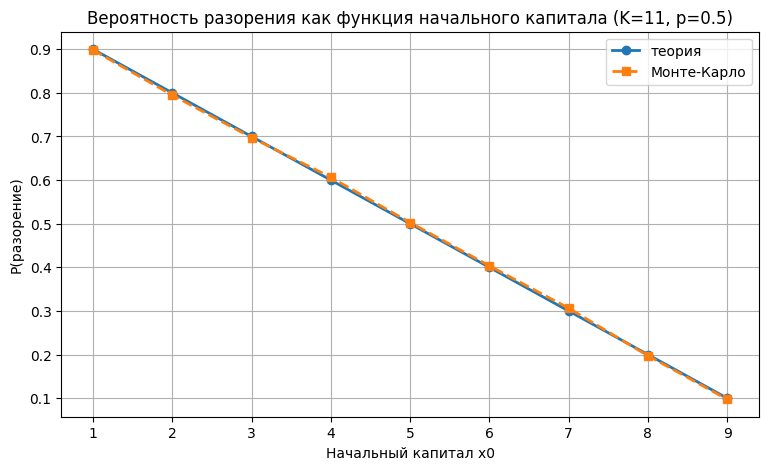

In [11]:
# Зависимость вероятности разорения от начального капитала
xs = np.arange(1, K-1)
P_emp_curve, P_th_curve = [], []
rng = np.random.default_rng(SEED)
for x in xs:
    P_emp_curve.append(simulate_ruin(K, p, x, N, rng))
    P_th_curve.append(theory_ruin(K, p, x))

plt.figure()
plt.plot(xs, P_th_curve, 'o-', label='теория', linewidth=2)
plt.plot(xs, P_emp_curve, 's--', label='Монте-Карло', linewidth=2)
plt.title(f'Вероятность разорения как функция начального капитала (K={K}, p={p})')
plt.xlabel('Начальный капитал x0')
plt.ylabel('P(разорение)')
plt.legend()
plt.show()


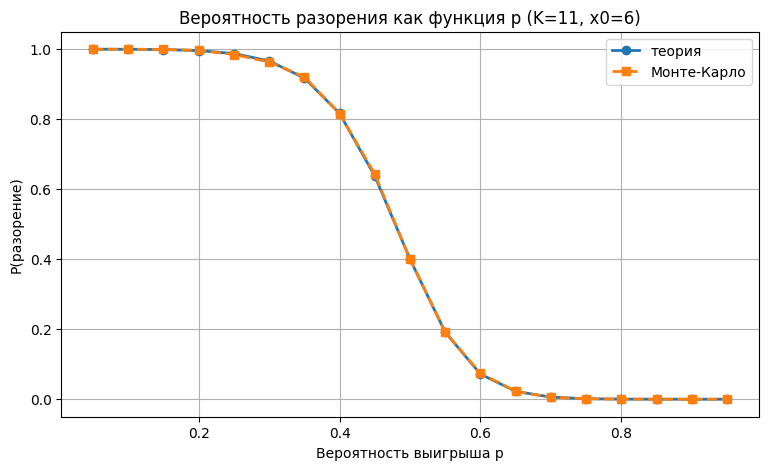

In [12]:
# Зависимость вероятности разорения от вероятности выигрыша p
ps = np.linspace(0.05, 0.95, 19)
P_emp_p, P_th_p = [], []
rng = np.random.default_rng(SEED)
for p_ in ps:
    P_emp_p.append(simulate_ruin(K, p_, x0, N, rng))
    P_th_p.append(theory_ruin(K, p_, x0))

plt.figure()
plt.plot(ps, P_th_p, 'o-', label='теория', linewidth=2)
plt.plot(ps, P_emp_p, 's--', label='Монте-Карло', linewidth=2)
plt.title(f'Вероятность разорения как функция p (K={K}, x0={x0})')
plt.xlabel('Вероятность выигрыша p')
plt.ylabel('P(разорение)')
plt.legend()
plt.show()


In [13]:
# Собственные значения матрицы P задачи о разорении (для справки)
eigs = np.linalg.eigvals(P_ruin)
print('Собственные значения P (задача о разорении):')
for e in sorted(eigs, key=lambda z: -abs(z)):
    print(f'  {e.real: .6f}{e.imag:+.6f}j  |.| = {abs(e):.4f}')
print(f'Число единичных собственных значений: {np.sum(np.isclose(eigs, 1.0))}')


Собственные значения P (задача о разорении):
   1.000000+0.000000j  |.| = 1.0000
   1.000000+0.000000j  |.| = 1.0000
   0.951057+0.000000j  |.| = 0.9511
  -0.951057+0.000000j  |.| = 0.9511
   0.809017+0.000000j  |.| = 0.8090
  -0.809017+0.000000j  |.| = 0.8090
   0.587785+0.000000j  |.| = 0.5878
  -0.587785+0.000000j  |.| = 0.5878
   0.309017+0.000000j  |.| = 0.3090
  -0.309017+0.000000j  |.| = 0.3090
  -0.000000+0.000000j  |.| = 0.0000
Число единичных собственных значений: 2


## Задание 3. Собственные значения и количество поглощающих состояний

**Теория.** В матрице переходных вероятностей МЦ кратность собственного значения $\lambda=1$ равна числу замкнутых классов сообщающихся состояний. В частности, если МЦ имеет $m$ поглощающих состояний, то $\lambda=1$ — собственное значение **кратности $m$**.

**Что делаем.** Конструируем три блочно-диагональные матрицы: с одним, двумя и тремя независимыми возвратными подцепями (а также делаем варианты с «настоящими» поглощающими состояниями), считаем собственные числа и проверяем теорию.


In [14]:
# Утилита: случайная стохастическая матрица размера n×n
def random_stochastic(n, rng=None):
    rng = rng or np.random.default_rng()
    M = rng.random((n, n))
    return M / M.sum(axis=1, keepdims=True)

# Сборка блочной МЦ из подцепей
def block_chain(blocks):
    n_total = sum(B.shape[0] for B in blocks)
    P = np.zeros((n_total, n_total))
    off = 0
    for B in blocks:
        k = B.shape[0]
        P[off:off+k, off:off+k] = B
        off += k
    return P

rng = np.random.default_rng(SEED)


In [15]:
# (а) 1 замкнутый класс (одна возвратная МЦ)
A1 = random_stochastic(6, rng)
e1 = np.linalg.eigvals(A1)

# (б) 2 замкнутых класса (две независимых МЦ)
A2 = block_chain([random_stochastic(5, rng), random_stochastic(4, rng)])
e2 = np.linalg.eigvals(A2)

# (в) 3 замкнутых класса (три независимых МЦ)
A3 = block_chain([random_stochastic(4, rng), random_stochastic(3, rng), random_stochastic(3, rng)])
e3 = np.linalg.eigvals(A3)

for name, eigs in [('1 класс', e1), ('2 класса', e2), ('3 класса', e3)]:
    units = np.sum(np.isclose(np.abs(eigs), 1.0, atol=1e-8) & (np.real(eigs) > 0.9))
    print(f'{name}: число |lambda|=1 ≈ {units}')
    print('  ', np.round(np.sort_complex(eigs)[::-1], 4))


1 класс: число |lambda|=1 ≈ 1
   [ 1.    +0.j      0.2318+0.j      0.0904+0.j      0.0188+0.1495j
  0.0188-0.1495j -0.2036+0.j    ]
2 класса: число |lambda|=1 ≈ 2
   [ 1.    +0.j      1.    +0.j      0.3378+0.j      0.1062+0.j
  0.0041+0.1283j  0.0041-0.1283j -0.0514+0.j     -0.1796+0.0934j
 -0.1796-0.0934j]
3 класса: число |lambda|=1 ≈ 3
   [ 1.    +0.j      1.    +0.j      1.    +0.j      0.5196+0.j
  0.3494+0.j      0.1672+0.j     -0.1801+0.0831j -0.1801-0.0831j
 -0.2264+0.1792j -0.2264-0.1792j]


m=1: число lambda=1 равно 1
m=2: число lambda=1 равно 2
m=3: число lambda=1 равно 3
m=4: число lambda=1 равно 4


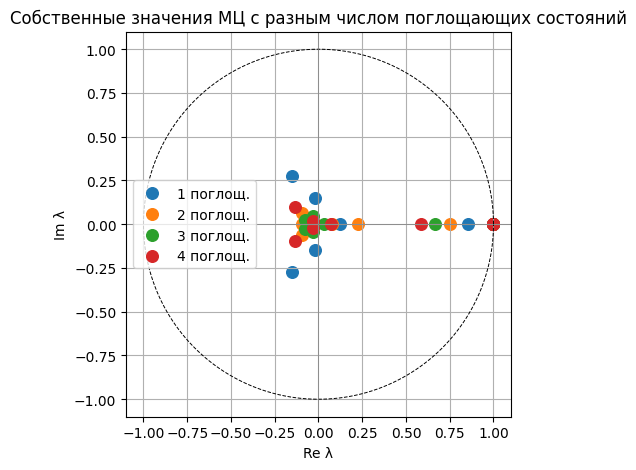

In [16]:
# Теперь — настоящие поглощающие состояния (по образцу задачи о разорении)
def absorbing_chain(m_absorb=2, n_transient=5, rng=None):
    rng = rng or np.random.default_rng()
    n = m_absorb + n_transient
    P = np.zeros((n, n))
    # m_absorb поглощающих состояний — на главной диагонали по 1
    for i in range(m_absorb):
        P[i, i] = 1.0
    # переходные состояния — случайные строки
    M = rng.random((n_transient, n))
    P[m_absorb:, :] = M / M.sum(axis=1, keepdims=True)
    return P

plt.figure()
for m in (1, 2, 3, 4):
    Pm = absorbing_chain(m, 6, rng)
    eigs = np.linalg.eigvals(Pm)
    plt.scatter(np.real(eigs), np.imag(eigs), s=70, label=f'{m} поглощ.')
    units = int(np.sum(np.isclose(eigs, 1.0)))
    print(f'm={m}: число lambda=1 равно {units}')
theta = np.linspace(0, 2*np.pi, 200)
plt.plot(np.cos(theta), np.sin(theta), 'k--', linewidth=0.7)
plt.axhline(0, color='gray', linewidth=0.5)
plt.axvline(0, color='gray', linewidth=0.5)
plt.gca().set_aspect('equal')
plt.title('Собственные значения МЦ с разным числом поглощающих состояний')
plt.xlabel('Re λ'); plt.ylabel('Im λ')
plt.legend()
plt.show()


## Выводы

1. **Задание 1.** Метод статистических испытаний даёт оценку стационарных вероятностей $\hat\pi_i$, которая сходится к аналитическому решению $\pi P = \pi$ с ростом длины траектории. Эмпирическая ошибка убывает приблизительно как $1/\sqrt N$ — это видно на графике в логарифмических осях.

2. **Задание 2.** Метод Монте‑Карло точно воспроизводит классическое решение задачи о разорении. При $p=q=1/2$ вероятность разорения линейна по начальному капиталу: $P(\text{разорение}\mid x_0)=(K-1-x_0)/(K-1)$. При $p\ne q$ функция геометрически смещается в пользу более «удачливого» игрока.

3. **Задание 3.** Кратность собственного значения $\lambda=1$ матрицы $P$ **равна числу замкнутых классов сообщающихся состояний** (в нашем случае — числу независимых возвратных подцепей или числу поглощающих состояний). Этот факт позволяет, не строя граф МЦ, по спектру матрицы определить количество эргодических компонент / поглощающих состояний.
